In [6]:
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv("olist_orders_dataset.csv")
items = pd.read_csv("olist_order_items_dataset.csv")

In [7]:
orders = orders.dropna(subset=["order_delivered_customer_date"])
orders = orders.drop_duplicates()
orders["month"] = pd.to_datetime(orders["order_purchase_timestamp"]).dt.to_period("M").astype(str)

In [8]:
totals = items.groupby("order_id")["price"].sum().reset_index()
df = orders.merge(totals, on="order_id")

report = df.groupby("month").agg(revenue=("price", "sum"),
                                 orders=("order_id", "count")).reset_index()
report["revenue"] = report["revenue"].round(2)
report.head()

,month,revenue,orders
0,2016-09,134.97,1
1,2016-10,40941.30,270
2,2016-12,10.90,1
3,2017-01,111798.36,750
4,2017-02,234223.40,1653


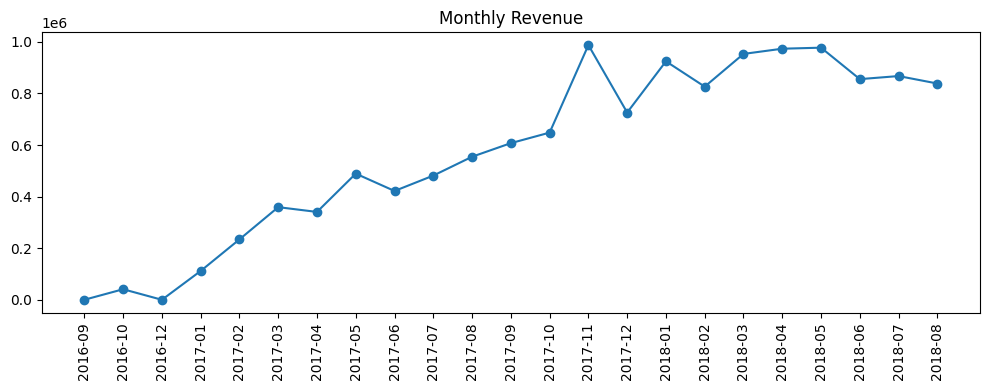

In [13]:
plt.figure(figsize=(10, 4))
plt.plot(report["month"], report["revenue"], marker="o")
plt.xticks(rotation=90)
plt.title("Monthly Revenue")
plt.tight_layout()
plt.show()


In [10]:
!pip install gspread -q
from google.colab import auth
auth.authenticate_user()

import gspread
from google.auth import default
creds, _ = default()
gc = gspread.authorize(creds)

In [11]:
sheet = gc.create("Olist Monthly Report")
ws = sheet.sheet1
ws.update([report.columns.tolist()] + report.values.tolist())
print("Report is ready:", sheet.url)

Report is ready: https://docs.google.com/spreadsheets/d/1UE_6SO2MdNwy9Lf-RTHBto2bUFl4kEiJogtjQi4fI_A


In [12]:
def run_report():
    ws.clear()
    ws.update([report.columns.tolist()] + report.values.tolist())
    print("Report updated")

run_report()

Report updated
